In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()
# 오류 발생시
sklearn.set_config(display="text")

[문제 1] 데이터 로드 & 증강 파이프라인 구성 (힌트 제공) (15점)

요구사항

- 입력 크기: 224 x 224

- 배치 크기: 32

- 훈련/검증 분리: 80 / 20

- 훈련(train)에만 증강 적용

- 클래스 수: 본인이 선택한 데이터셋 기준으로 명시 (예: 2진 분류 또는 다중 분류)

In [58]:
base_path = r"C:\kdt_0900_osh\ml\resource\datasets"

In [3]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

os.makedirs(base_path, exist_ok=True)
# https://www.kaggle.com/datasets/yousefmohamed20/sentiment-images-classifier
api.dataset_download_files(r"yousefmohamed20/sentiment-images-classifier", path=base_path, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/yousefmohamed20/sentiment-images-classifier
다운로드 완료


In [59]:
file_path = os.path.join(base_path, r"6 Emotions for image classification")
file_path

'C:\\kdt_0900_osh\\ml\\resource\\datasets\\6 Emotions for image classification'

In [60]:
base_dataset = ImageFolder(file_path, transform=None)

In [61]:
base_dataset

Dataset ImageFolder
    Number of datapoints: 1198
    Root location: C:\kdt_0900_osh\ml\resource\datasets\6 Emotions for image classification

In [62]:
train_subset, temp_subset = train_test_split(base_dataset, test_size=0.2, random_state=42)
val_subset, test_subset = train_test_split(temp_subset, test_size=0.5, random_state=42)

In [80]:
len(train_subset), len(val_subset), len(test_subset)

val_subset + test_subset

[(<PIL.Image.Image image mode=RGB size=300x238>, 2),
 (<PIL.Image.Image image mode=RGB size=612x408>, 3),
 (<PIL.Image.Image image mode=RGB size=1920x1008>, 0),
 (<PIL.Image.Image image mode=RGB size=612x408>, 3),
 (<PIL.Image.Image image mode=RGB size=612x406>, 3),
 (<PIL.Image.Image image mode=RGB size=640x427>, 2),
 (<PIL.Image.Image image mode=RGB size=233x377>, 0),
 (<PIL.Image.Image image mode=RGB size=1024x683>, 3),
 (<PIL.Image.Image image mode=RGB size=360x246>, 0),
 (<PIL.Image.Image image mode=RGB size=612x408>, 4),
 (<PIL.Image.Image image mode=RGB size=1000x717>, 2),
 (<PIL.Image.Image image mode=RGB size=640x360>, 3),
 (<PIL.Image.Image image mode=RGB size=468x286>, 0),
 (<PIL.Image.Image image mode=RGB size=800x534>, 4),
 (<PIL.Image.Image image mode=RGB size=612x408>, 3),
 (<PIL.Image.Image image mode=RGB size=658x370>, 2),
 (<PIL.Image.Image image mode=RGB size=612x437>, 3),
 (<PIL.Image.Image image mode=RGB size=612x408>, 0),
 (<PIL.Image.Image image mode=RGB size=612

In [64]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [65]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

In [66]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

target_transform = lambda y: torch.tensor([y], dtype=torch.float32)

In [81]:
train_dataset = DatasetWrapper(train_subset, transform=train_transform)
val_dataset = DatasetWrapper(val_subset, transform=test_transform)
test_dataset = DatasetWrapper(test_subset, transform=test_transform)
temp_dataset = DatasetWrapper(val_subset + test_subset, transform=test_transform)

In [68]:
len(train_dataset), len(val_dataset), len(test_dataset), len(base_dataset)

(958, 120, 120, 1198)

In [72]:
class_dict = dict(enumerate(base_dataset.classes))
class_dict

{0: 'anger', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'pain', 5: 'sad'}

In [82]:
train_dataloader = DataLoader(train_dataset, shuffle=True, batch_size=32)
val_dataloader = DataLoader(val_dataset, shuffle=False, batch_size=32)
test_dataloader = DataLoader(test_dataset, shuffle=False, batch_size=32)
temp_dataloader = DataLoader(temp_dataset, batch_size=32)

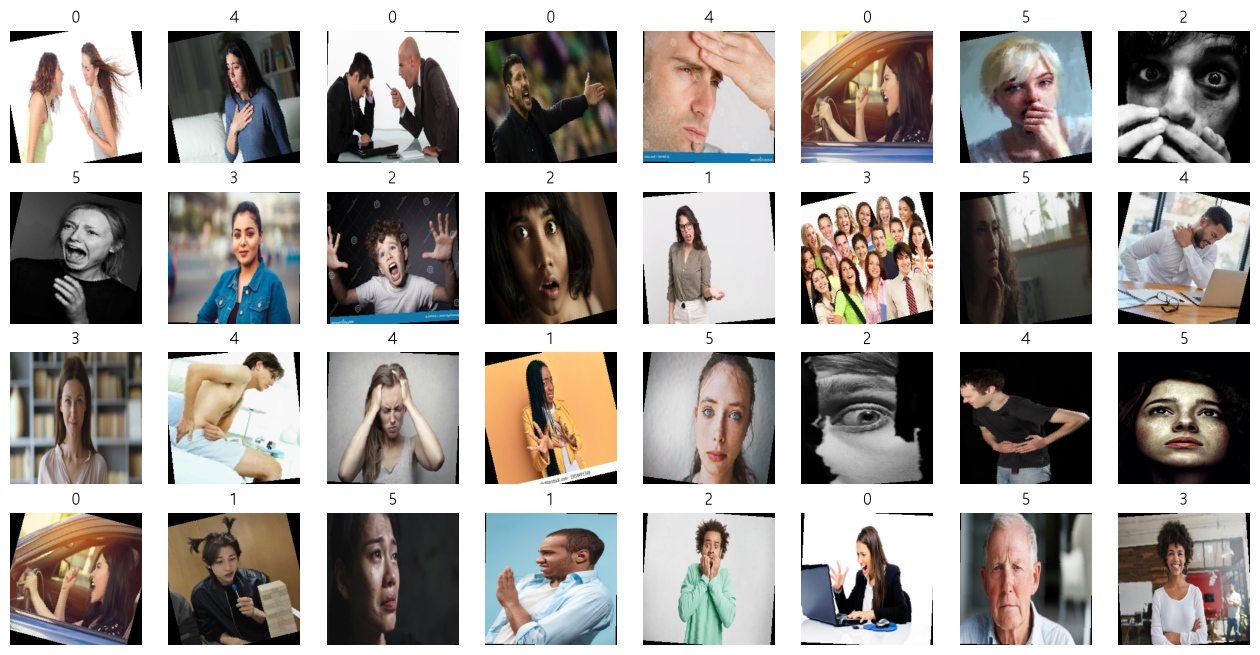

tensor([0, 4, 0, 0, 4, 0, 5, 2, 5, 3, 2, 2, 1, 3, 5, 4, 3, 4, 4, 1, 5, 2, 4, 5,
        0, 1, 5, 1, 2, 0, 5, 3])


In [28]:
imgs, labels = next(iter(train_dataloader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    img = img * std + mean
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(label.item())
    ax.axis("off")

plt.show()

print(labels)

In [ ]:
# 18. 캣도그 구별 모델 코드 보고 하기

[문제 2] 베이스 모델 선택 & 선택 이유(서술) (15점)

요구사항 다음 조건을 만족하도록 베이스 모델 1개를 선택하고, 선택 이유를 8~12줄로 서술하라. 서술 항목(필수 포함)

1. 데이터 특성(클래스 수, 데이터 규모 추정, 난이도, 이미지 특징)

2. 모델 트레이드오프(정확도 vs 속도 vs 모델 크기/파라미터 수)

3. 실행 환경 고려(로컬 GPU/MPS, Colab T4, 학습 시간 등)

4. 위험요소(과적합, 배경 편향, 전처리 호환 등)와 대응 1개

6개 감정 클래스(anger, disgust, fear, happy, pain, sad)가 존재하고, 데이터가 학습 958장·검증 120장·테스트 120장이다.
이미지가 얼굴 정면 사진, 측면 사진, 단독 사진, 단체사진, 얼굴 일부분이 가려진 사진, 흑백사진 등 
이 때 데이터의 총량이 1198개로 많지 않다. 때문에 사전학습 가중치가 들어가는 전이학습 모델을 사용하는 것이 좋다.
더 나아가 추후에 사람의 표정을 보고 감정을 분석하는 모델이 사용될 법한 상황을 생각해봤을 때 심리치료나 정신과 분야에서 사용될 가능성이 높다.
이는 이 모델이 정해진 장소에서 정적으로 사용될 것이라는 뜻으로, 굳이 MobileNet을 사용할 필요가 없다.

In [22]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cuda


In [41]:
model_weights_path = os.path.join(base_path, "weights")
os.makedirs(model_weights_path, exist_ok=True)
torch.hub.set_dir(model_weights_path)

model = models.resnet18(weights="IMAGENET1K_V1").to(device)

[문제 3] 전이학습 모델 구현 & 훈련(Feature Extraction) (40점)

요구사항(공통)

선택한 베이스 모델로 특징추출 전이학습 모델을 구성하고 학습하라.

필수 조건

- 사전 모델 상위 분류기 제거 및 교체

- base model은 동결(requires_grad = False) 유지

- 분류기 헤드(필수):

- nn.AdaptiveAvgPool2d((1, 1)) (GAP 적용)

- nn.Dropout(권장)

- nn.Linear(in_features, num_classes)

- optimizer: Adam, learning_rate=0.001

- 체크포인트:

- 검증 정확도 기준 최고 성능 갱신 시 torch.save로 best 모델 저장

모델 프리징

In [44]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [43]:
for param in model.parameters():
    param.requires_grad = False

In [73]:
model.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Linear(128,6),
).to(device)

In [74]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device="cpu"):
    model.train()
    sum_losses = 0.0
    sum_accs = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        batch_loss = 0.0
        
        # 학습
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 다중 클래스의 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] Batch Loss: {batch_loss:.4f}, Batch Accuracy: {acc:.2f}%")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [75]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device="cpu"):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)
    
    return avg_loss, avg_acc

In [76]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0

    # 학습
    print(f"========================={model_name} 학습 시작 ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
        print(f"[Epoch: {epoch + 1}] | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"========================={model_name} 학습 종료 ============================")
    return history

In [77]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [83]:
history = train_model_multiclass(
    model=model,
    model_name="Resnet-emotion",
    train_loader=train_dataloader,
    val_loader=temp_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=100,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

=========================Resnet-emotion 학습 시작 ============================
[Batch 20/30] Batch Loss: 0.3803, Batch Accuracy: 90.62%
[Epoch: 1] | Train Loss: 0.5469 | Train Accuracy: 79.83%
[Epoch: 1] | Validation Loss: 1.2491 | Validation Accuracy: 60.55%
[Batch 20/30] Batch Loss: 0.4870, Batch Accuracy: 84.38%
[Epoch: 2] | Train Loss: 0.5209 | Train Accuracy: 79.32%
[Epoch: 2] | Validation Loss: 1.3556 | Validation Accuracy: 58.98%
[Batch 20/30] Batch Loss: 0.5010, Batch Accuracy: 84.38%
[Epoch: 3] | Train Loss: 0.5662 | Train Accuracy: 79.23%
[Epoch: 3] | Validation Loss: 1.2703 | Validation Accuracy: 58.59%
[Batch 20/30] Batch Loss: 0.4106, Batch Accuracy: 84.38%
[Epoch: 4] | Train Loss: 0.5552 | Train Accuracy: 79.26%
[Epoch: 4] | Validation Loss: 1.2750 | Validation Accuracy: 60.16%
[Batch 20/30] Batch Loss: 0.3615, Batch Accuracy: 87.50%
[Epoch: 5] | Train Loss: 0.5140 | Train Accuracy: 81.19%
[Epoch: 5] | Validation Loss: 1.5470 | Validation Accuracy: 54.30%
[Batch 20/30] Batch 

In [85]:
evaluate_multiclass(
    model=model,
    dataloader=temp_dataloader,
    criterion=criterion,
    device=device
)

(1.8630033284425735, 59.765625)

In [84]:
evaluate_multiclass?

Signature: evaluate_multiclass(model, dataloader, criterion, device='cpu')
Docstring: <no docstring>
File:      ~\appdata\local\temp\ipykernel_7440\280645775.py
Type:      function